# 04 · Análise imobiliária: distribuição do preço do m²

**Mobilidade e mercado imobiliário no Rio de Janeiro** · AEDV · FGV EMAp · 2026.2


Este notebook responde às perguntas de domínio 1 a 4, que descrevem o preço do m² dos imóveis residenciais negociados no município antes de qualquer cruzamento com transporte:

1. Como os valores dos imóveis negociados pelo ITBI se distribuem no município do Rio de Janeiro?
2. Qual é o valor médio e mediano do m² dos imóveis analisados e qual é a diferença entre essas medidas?
3. Qual é a dispersão dos valores do m², considerando variância, desvio padrão e amplitude?
4. Os valores do m² apresentam distribuição semelhante entre diferentes bairros ou regiões da cidade?

As respostas servem de linha de base para as perguntas de transporte. Antes de perguntar se o m² é mais caro perto de uma estação, é preciso saber quanto ele varia naturalmente pela cidade e entre bairros.

Este notebook contém o código da análise. As respostas e a discussão dos resultados estão no artigo do projeto, em `notebooks/05_artigo.ipynb`.

**Entrada:** `data/processed/itbi_residencial_2011_2024_geocodificado_completo.csv.gz`, gerado no notebook 01.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap, LogNorm

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Funciona abrindo o notebook a partir da raiz do repositório ou de notebooks/
ARQ = "itbi_residencial_2011_2024_geocodificado_completo.csv.gz"
for raiz in [Path("."), Path("..")]:
    if (raiz / "data" / "processed" / ARQ).exists():
        CAMINHO = raiz / "data" / "processed" / ARQ
        break
else:
    raise FileNotFoundError(f"Não encontrei data/processed/{ARQ}")

# Estilo dos gráficos: marcas finas, grade discreta, uma cor por papel
AZUL, LARANJA, CINZA, TINTA = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
SEQ = LinearSegmentedColormap.from_list(
    "azuis", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bdbcb6", "axes.labelcolor": TINTA, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
    "text.parse_math": False,   # para o "R$" não virar fórmula
})

def reais(v, casas=0):
    # Formata no padrão brasileiro: R$ 7.407
    s = f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"R$ {s}"

def nome(bairro):
    # "RICARDO DE ALBUQUERQUE" -> "Ricardo de Albuquerque"
    return " ".join(p if p in {"de", "da", "do", "dos", "das", "e"} else p.capitalize()
                    for p in str(bairro).lower().split())

fmt_reais = mticker.FuncFormatter(lambda v, _: reais(v))
fmt_milhar = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))

def tabela(d, formatos="{:,.0f}"):
    # Formata uma tabela no padrão brasileiro (1.234,5) sem depender do jinja2,
    # que o DataFrame.style exige. formatos: um formato para tudo ou {coluna: formato}.
    troca = str.maketrans({",": ".", ".": ","})
    out = pd.DataFrame(index=d.index)
    for col in d.columns:
        f = formatos if isinstance(formatos, str) else formatos.get(col, "{:,.0f}")
        out[col] = [f.format(v).translate(troca) if pd.notna(v) else "" for v in d[col]]
    return out

## 1. Preparação

### 1.1 Leitura

In [2]:
bruto = pd.read_csv(CAMINHO, low_memory=False)
print(f"{len(bruto):,} transações residenciais · {bruto.ano.min()}–{bruto.ano.max()} · "
      f"{bruto.nm_bairro_norm.nunique()} bairros".replace(",", "."))
bruto[["ano", "mes", "nm_bairro_norm", "ds_imovel_tipologia", "valor_transacoes",
       "area", "valor_m2", "valor_m2_suspeito", "qualidade_geocodificacao"]].head()

441.669 transações residenciais · 2011–2024 · 156 bairros


,ano,mes,nm_bairro_norm,ds_imovel_tipologia,valor_transacoes,area,valor_m2,valor_m2_suspeito,qualidade_geocodificacao
0,2011,7,GUADALUPE,PROLETARIO CASA/APTO,74000.0,49.0,1510.204082,False,alta_precisao
1,2011,7,ANCHIETA,CASA,140000.0,66.0,2121.212121,False,alta_precisao
2,2011,7,ANCHIETA,CASA,80000.0,92.0,869.565217,False,alta_precisao
3,2011,7,ANCHIETA,CASA,140000.0,50.0,2800.000000,False,baixa_precisao
4,2011,7,PARQUE ANCHIETA,APARTAMENTO,95000.0,45.0,2111.111111,False,alta_precisao


### 1.2 Filtros e justificativa

A base já vem com a limpeza feita no notebook 01: só transações residenciais, escapes de texto corrigidos e `parte_transferida` igual a 100%. Aqui aplicamos **um único filtro adicional**, a exclusão das transações com `valor_m2_suspeito = True`. São valores de m² implausíveis para venda de imóvel, com mediana em torno de R$ 200/m², ou dezenas de milhões por m², como um apartamento de 118 m² em Ipanema declarado por R$ 5,67 bilhões. Mantê-las não acrescenta informação sobre o mercado e destrói qualquer média e desvio padrão, como mostra a seção 4.

Não cortamos por percentil. Mesmo depois do filtro restam alguns valores estranhos nas duas pontas, mas a decisão de cortá-los é arbitrária, e a pergunta 3 trata justamente da dispersão. Em vez de esconder esses valores, a seção 4 mostra quanto cada medida muda com e sem eles. Nas comparações entre regiões usamos medidas robustas (mediana e quartis), que quase não se alteram com esses casos.

As linhas com `status_limpeza = "revisao"` (1.200, sem número ou sem logradouro) **permanecem**: o problema delas é de endereço, não de preço. Só ficam de fora do mapa e, quando não têm bairro, das comparações por bairro.

A localização no mapa usa apenas `lat_analise` e `lon_analise`, preenchidas somente para geocodificação de alta precisão.

In [3]:
# Garante que a coluna seja booleana mesmo se vier como texto ("True"/"False")
if bruto.valor_m2_suspeito.dtype != bool:
    bruto["valor_m2_suspeito"] = bruto.valor_m2_suspeito.astype(str).str.strip().str.lower().eq("true")

df = bruto.loc[~bruto.valor_m2_suspeito].copy()

filtros = pd.DataFrame({
    "transações": [len(bruto), bruto.valor_m2_suspeito.sum(), len(df)],
}, index=["base completa", "excluídas: valor_m2_suspeito", "base de análise"])
tabela(filtros)

,transações
base completa,441.669
excluídas: valor_m2_suspeito,1.514
base de análise,440.155


### 1.3 Correção pela inflação

Os valores do ITBI são nominais. Entre julho de 2011 e dezembro de 2024 o IPCA acumulou cerca de 114%, ou seja, os preços mais que dobraram só por inflação. Comparar diretamente um m² de 2012 com um de 2024, ou calcular a variância juntando os dois, mistura inflação com diferença real de preço. A dispersão ficaria inflada e a média seria puxada para os anos recentes.

Por isso **todos os valores deste notebook estão em reais de dezembro de 2024** (`m2_real`). Usamos a variação anual do IPCA (IBGE) e interpolamos geometricamente dentro de cada ano pelo mês da transação. É uma aproximação da série mensal, com erro de poucas décimas de ponto percentual, suficiente para análise descritiva.

In [4]:
# IPCA, variação acumulada no ano (%) — IBGE
IPCA = {2011: 6.50, 2012: 5.84, 2013: 5.91, 2014: 6.41, 2015: 10.67, 2016: 6.29, 2017: 2.95,
        2018: 3.75, 2019: 4.31, 2020: 4.52, 2021: 10.06, 2022: 5.79, 2023: 4.62, 2024: 4.83}

indice_dez = {2010: 1.0}
for a in range(2011, 2025):
    indice_dez[a] = indice_dez[a - 1] * (1 + IPCA[a] / 100)

# índice no mês m do ano a ≈ índice de dez/(a-1) × (1 + IPCA_a)^(m/12)
indice = np.array([indice_dez[a - 1] * (1 + IPCA[a] / 100) ** (m / 12) for a, m in zip(df.ano, df.mes)])
df["fator_ipca"] = indice_dez[2024] / indice
df["m2_real"] = df.valor_m2 * df.fator_ipca

print(f"Fator de correção jul/2011 → dez/2024: {df.loc[(df.ano == 2011) & (df.mes == 7), 'fator_ipca'].iloc[0]:.3f}")
print(f"Fator de correção dez/2024 → dez/2024: {df.loc[(df.ano == 2024) & (df.mes == 12), 'fator_ipca'].iloc[0]:.3f}")

Fator de correção jul/2011 → dez/2024: 2.142
Fator de correção dez/2024 → dez/2024: 1.000


### 1.4 Áreas de Planejamento

Para a pergunta 4, além de bairros, agrupamos a cidade nas cinco **Áreas de Planejamento (AP)** da Prefeitura. Bairros são muitos (156 com transações) e alguns têm poucas vendas. As APs são poucas, oficiais e cada uma reúne muitas transações. A base não traz a AP, então o mapeamento bairro → AP está abaixo, seguindo a divisão administrativa do IPP.

In [5]:
AREAS_PLANEJAMENTO = {
    'AP1 · Centro': [
        'SAUDE', 'GAMBOA', 'SANTO CRISTO', 'CAJU', 'CENTRO', 'CATUMBI',
        'RIO COMPRIDO', 'CIDADE NOVA', 'ESTACIO', 'IMPERIAL DE SAO CRISTOVAO', 'MANGUEIRA', 'BENFICA',
        'VASCO DA GAMA', 'PAQUETA', 'SANTA TERESA'],
    'AP2 · Zona Sul e Tijuca': [
        'FLAMENGO', 'GLORIA', 'LARANJEIRAS', 'CATETE', 'COSME VELHO', 'BOTAFOGO',
        'HUMAITA', 'URCA', 'LEME', 'COPACABANA', 'IPANEMA', 'LEBLON',
        'LAGOA', 'JARDIM BOTANICO', 'GAVEA', 'VIDIGAL', 'SAO CONRADO', 'ROCINHA',
        'PRACA DA BANDEIRA', 'TIJUCA', 'ALTO DA BOA VISTA', 'MARACANA', 'VILA ISABEL', 'ANDARAI',
        'GRAJAU'],
    'AP3 · Zona Norte': [
        'RAMOS', 'BONSUCESSO', 'OLARIA', 'MANGUINHOS', 'PENHA', 'PENHA CIRCULAR',
        'BRAZ DE PINA', 'CORDOVIL', 'PARADA DE LUCAS', 'VIGARIO GERAL', 'JARDIM AMERICA', 'HIGIENOPOLIS',
        'JACARE', 'MARIA DA GRACA', 'DEL CASTILHO', 'INHAUMA', 'ENGENHO DA RAINHA', 'TOMAS COELHO',
        'JACAREZINHO', 'SAO FRANCISCO XAVIER', 'ROCHA', 'RIACHUELO', 'SAMPAIO', 'ENGENHO NOVO',
        'LINS DE VASCONCELOS', 'MEIER', 'TODOS OS SANTOS', 'CACHAMBI', 'ENGENHO DE DENTRO', 'AGUA SANTA',
        'ENCANTADO', 'PIEDADE', 'ABOLICAO', 'PILARES', 'VILA KOSMOS', 'VICENTE DE CARVALHO',
        'VILA DA PENHA', 'VISTA ALEGRE', 'IRAJA', 'COLEGIO', 'CAMPINHO', 'QUINTINO BOCAIUVA',
        'CAVALCANTI', 'ENGENHEIRO LEAL', 'CASCADURA', 'MADUREIRA', 'VAZ LOBO', 'TURIACU',
        'ROCHA MIRANDA', 'HONORIO GURGEL', 'OSWALDO CRUZ', 'BENTO RIBEIRO', 'MARECHAL HERMES', 'GUADALUPE',
        'ANCHIETA', 'PARQUE ANCHIETA', 'RICARDO DE ALBUQUERQUE', 'COELHO NETO', 'ACARI', 'BARROS FILHO',
        'COSTA BARROS', 'PAVUNA', 'PARQUE COLUMBIA', 'RIBEIRA', 'ZUMBI', 'CACUIA',
        'PITANGUEIRAS', 'PRAIA DA BANDEIRA', 'COCOTA', 'BANCARIOS', 'FREGUESIA ILHA', 'JARDIM GUANABARA',
        'JARDIM CARIOCA', 'TAUA', 'MONERO', 'PORTUGUESA', 'GALEAO', 'CIDADE UNIVERSITARIA',
        'COMPLEXO DO ALEMAO', 'MARE'],
    'AP4 · Barra e Jacarepaguá': [
        'JACAREPAGUA', 'ANIL', 'GARDENIA AZUL', 'CIDADE DE DEUS', 'CURICICA', 'FREGUESIA JACAREPAGUA',
        'PECHINCHA', 'TAQUARA', 'TANQUE', 'PRACA SECA', 'VILA VALQUEIRE', 'JOA',
        'ITANHANGA', 'BARRA DA TIJUCA', 'CAMORIM', 'VARGEM PEQUENA', 'VARGEM GRANDE', 'RECREIO DOS BANDEIRANTES',
        'GRUMARI'],
    'AP5 · Zona Oeste': [
        'DEODORO', 'VILA MILITAR', 'CAMPO DOS AFONSOS', 'JARDIM SULACAP', 'MAGALHAES BASTOS', 'REALENGO',
        'PADRE MIGUEL', 'BANGU', 'SENADOR CAMARA', 'GERICINO', 'SANTISSIMO', 'CAMPO GRANDE',
        'SENADOR VASCONCELOS', 'INHOAIBA', 'COSMOS', 'PACIENCIA', 'SANTA CRUZ', 'SEPETIBA',
        'GUARATIBA', 'BARRA DE GUARATIBA', 'PEDRA DE GUARATIBA'],
}

BAIRRO_AP = {b: ap for ap, bairros in AREAS_PLANEJAMENTO.items() for b in bairros}
ORDEM_AP = list(AREAS_PLANEJAMENTO)
df["ap"] = pd.Categorical(df.nm_bairro_norm.map(BAIRRO_AP), categories=ORDEM_AP, ordered=True)

sem_ap = df.loc[df.ap.isna() & df.nm_bairro_norm.notna(), "nm_bairro_norm"].unique()
print("Bairros sem AP:", list(sem_ap) or "nenhum")
print("Transações sem bairro:", df.nm_bairro_norm.isna().sum())
df.ap.value_counts(sort=False).to_frame("transações")

Bairros sem AP: nenhum
Transações sem bairro: 92


,transações
ap,
AP1 · Centro,23251
AP2 · Zona Sul e Tijuca,119263
AP3 · Zona Norte,103501
AP4 · Barra e Jacarepaguá,157315
AP5 · Zona Oeste,36733


## 2. Pergunta 1 — Como os valores se distribuem?

### 2.1 Forma da distribuição

Na escala linear, a distribuição do m² se concentra entre R$ 3 mil e R$ 12 mil e tem uma cauda longa à direita. Na escala logarítmica a forma fica quase simétrica. Esse é o padrão típico de preços, que variam de forma multiplicativa: um bairro custar o dobro de outro é mais natural que custar R$ 5 mil a mais. Por isso os gráficos seguintes usam escala log quando comparam grupos.

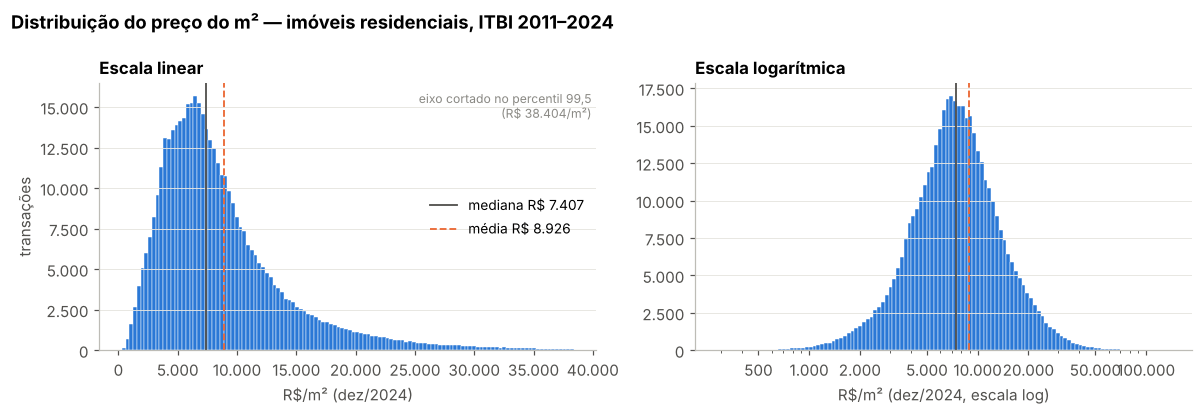

assimetria (skewness): 2.97 na escala linear · -0.13 na escala log
percentis (R$/m²): P5 R$ 2.595 · P25 R$ 5.055 · P50 R$ 7.407 · P75 R$ 10.845 · P95 R$ 20.422


In [6]:
x = df.m2_real
media, mediana = x.mean(), x.median()
corte = x.quantile(0.995)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axs[0]
ax.hist(x[x <= corte], bins=120, color=AZUL, edgecolor="white", linewidth=0.3)
ax.set_title("Escala linear")
ax.set_xlabel("R$/m² (dez/2024)")
ax.set_ylabel("transações")
ax.text(0.99, 0.97, f"eixo cortado no percentil 99,5\n({reais(corte)}/m²)", transform=ax.transAxes,
        ha="right", va="top", fontsize=8, color=CINZA)

ax = axs[1]
bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 120)
ax.hist(x, bins=bins, color=AZUL, edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
ax.set_title("Escala logarítmica")
ax.set_xlabel("R$/m² (dez/2024, escala log)")
ax.set_xticks([500, 1000, 2000, 5000, 10000, 20000, 50000, 100000])

for ax in axs:
    ax.xaxis.set_major_formatter(fmt_milhar)
    ax.yaxis.set_major_formatter(fmt_milhar)
    ax.axvline(mediana, color=TINTA, lw=1.2)
    ax.axvline(media, color=LARANJA, lw=1.2, ls="--")
    ax.grid(axis="x", visible=False)
from matplotlib.lines import Line2D
axs[0].legend(handles=[Line2D([], [], color=TINTA, lw=1.2, label=f"mediana {reais(mediana)}"),
                       Line2D([], [], color=LARANJA, lw=1.2, ls="--", label=f"média {reais(media)}")],
              loc="center right", fontsize=9)

fig.suptitle("Distribuição do preço do m² — imóveis residenciais, ITBI 2011–2024", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

print(f"assimetria (skewness): {x.skew():.2f} na escala linear · {np.log(x).skew():.2f} na escala log")
print("percentis (R$/m²):", " · ".join(f"P{int(q*100)} {reais(x.quantile(q))}" for q in [.05, .25, .5, .75, .95]))

### 2.2 Distribuição por tipo de imóvel

O ITBI residencial mistura apartamentos, que são 85% das transações, e casas. Os dois tipos têm preços de m² diferentes: a área da casa inclui a construção em terreno próprio, e as casas se concentram em bairros mais baratos. Vale ver os dois antes de seguir, porque a composição por tipo muda de uma região para outra.

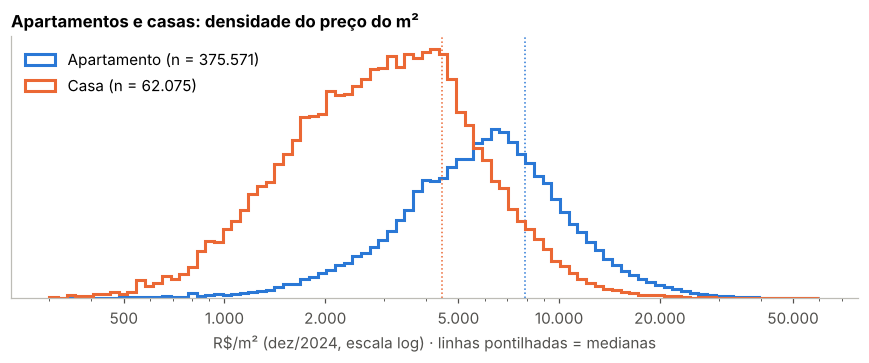

,transações,média,mediana,p25,p75,% do total
tipo,,,,,,
APARTAMENTO,375.571,9.526,7.935,5.655,11.475,"85,3"
CASA,62.075,5.469,4.454,2.966,6.592,"14,1"
PROLETÁRIO (casa/apto),2.509,4.685,3.741,1.966,6.245,"0,6"


In [7]:
tipo = df.ds_imovel_tipologia.where(df.ds_imovel_tipologia.isin(["APARTAMENTO", "CASA"]), "PROLETÁRIO (casa/apto)")
resumo_tipo = (df.assign(tipo=tipo).groupby("tipo").m2_real
               .agg(transações="size", média="mean", mediana="median",
                    p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75)))
resumo_tipo["% do total"] = 100 * resumo_tipo["transações"] / resumo_tipo["transações"].sum()

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(np.log10(300), np.log10(60000), 90)
for t, cor in [("APARTAMENTO", AZUL), ("CASA", LARANJA)]:
    v = df.loc[tipo == t, "m2_real"]
    ax.hist(v, bins=bins, density=True, histtype="step", lw=2, color=cor, label=f"{t.title()} (n = {len(v):,})".replace(",", "."))
    ax.axvline(v.median(), color=cor, lw=1, ls=":")
ax.set_xscale("log")
ax.set_xticks([500, 1000, 2000, 5000, 10000, 20000, 50000])
ax.xaxis.set_major_formatter(fmt_milhar)
ax.set_yticks([])
ax.grid(False)
ax.set_xlabel("R$/m² (dez/2024, escala log) · linhas pontilhadas = medianas")
ax.set_title("Apartamentos e casas: densidade do preço do m²")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

tabela(resumo_tipo, {"transações": "{:,.0f}", "média": "{:,.0f}", "mediana": "{:,.0f}",
                          "p25": "{:,.0f}", "p75": "{:,.0f}", "% do total": "{:.1f}"})

### 2.3 Distribuição no espaço

O mapa usa as 72% de transações com geocodificação de alta precisão. Cada hexágono tem cerca de 600 m de largura e mostra a mediana do m² das transações dentro dele, com pelo menos 10 vendas. Antes de ler o mapa, é preciso conferir se a geocodificação de alta precisão cobre as regiões de forma parecida. Se uma região tivesse muito menos pontos localizados, o mapa a sub-representaria.

In [8]:
geo = df.dropna(subset=["lat_analise", "lon_analise"])
cobertura = (df.groupby("ap", observed=True).lat_analise.apply(lambda s: s.notna().mean() * 100)
             .rename("% com coordenada de alta precisão").round(1))
print(f"Transações no mapa: {len(geo):,} de {len(df):,} ({len(geo)/len(df):.0%})".replace(",", "."))
cobertura.to_frame()

Transações no mapa: 318.709 de 440.155 (72%)


,% com coordenada de alta precisão
ap,
AP1 · Centro,81.5
AP2 · Zona Sul e Tijuca,90.0
AP3 · Zona Norte,84.2
AP4 · Barra e Jacarepaguá,53.3
AP5 · Zona Oeste,58.7


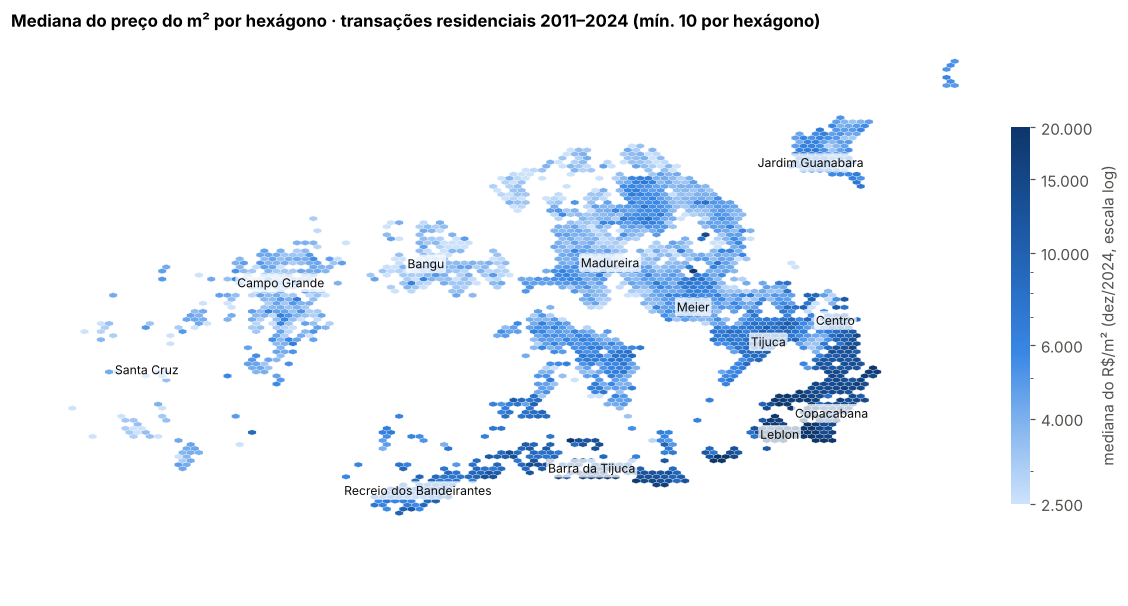

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
hb = ax.hexbin(geo.lon_analise, geo.lat_analise, C=geo.m2_real, reduce_C_function=np.median,
               gridsize=110, mincnt=10, cmap=SEQ, norm=LogNorm(vmin=2500, vmax=20000),
               linewidths=0.15, edgecolors="white")
ax.set_aspect(1 / np.cos(np.deg2rad(-22.92)))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)

cb = fig.colorbar(hb, ax=ax, shrink=0.6, pad=0.01)
cb.set_label("mediana do R$/m² (dez/2024, escala log)", color=TINTA)
cb.set_ticks([2500, 4000, 6000, 10000, 15000, 20000])
cb.ax.yaxis.set_major_formatter(fmt_milhar)
cb.ax.yaxis.set_minor_formatter(mticker.NullFormatter())
cb.outline.set_visible(False)

# alguns bairros de referência, posicionados pela mediana das coordenadas
ref = ["LEBLON", "COPACABANA", "CENTRO", "TIJUCA", "MEIER", "MADUREIRA", "BARRA DA TIJUCA",
       "RECREIO DOS BANDEIRANTES", "CAMPO GRANDE", "SANTA CRUZ", "BANGU", "JARDIM GUANABARA"]
pos = geo.groupby("nm_bairro_norm")[["lon_analise", "lat_analise"]].median()
for b in ref:
    if b in pos.index:
        lon, lat = pos.loc[b]
        ax.annotate(nome(b), (lon, lat), fontsize=8, color="#0b0b0b", ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))

ax.set_title("Mediana do preço do m² por hexágono · transações residenciais 2011–2024 (mín. 10 por hexágono)")
fig.tight_layout()
plt.show()

## 3. Pergunta 2 — Média, mediana e a diferença entre elas

In [10]:
def medidas_centrais(s):
    return pd.Series({"transações": len(s), "média": s.mean(), "mediana": s.median(),
                      "média − mediana": s.mean() - s.median(),
                      "média / mediana": s.mean() / s.median()})

tab_centro = pd.DataFrame({
    "R$/m² corrigido (dez/2024)": medidas_centrais(df.m2_real),
    "R$/m² nominal (sem correção)": medidas_centrais(df.valor_m2),
}).T
print(f"Transações com m² abaixo da média: {(df.m2_real < df.m2_real.mean()).mean():.0%}")
tabela(tab_centro, {"transações": "{:,.0f}", "média": "R$ {:,.0f}", "mediana": "R$ {:,.0f}",
                         "média − mediana": "R$ {:,.0f}", "média / mediana": "{:.2f}"})

Transações com m² abaixo da média: 63%


,transações,média,mediana,média − mediana,média / mediana
R$/m² corrigido (dez/2024),440.155,R$ 8.926,R$ 7.407,R$ 1.519,"1,21"
R$/m² nominal (sem correção),440.155,R$ 6.230,R$ 5.200,R$ 1.030,"1,20"


A diferença não se explica por um punhado de casos extremos. Ela aparece em todos os anos e em todas as regiões, porque faz parte da forma da distribuição. Separar por ano mostra isso, e mostra também a evolução do preço real no período.

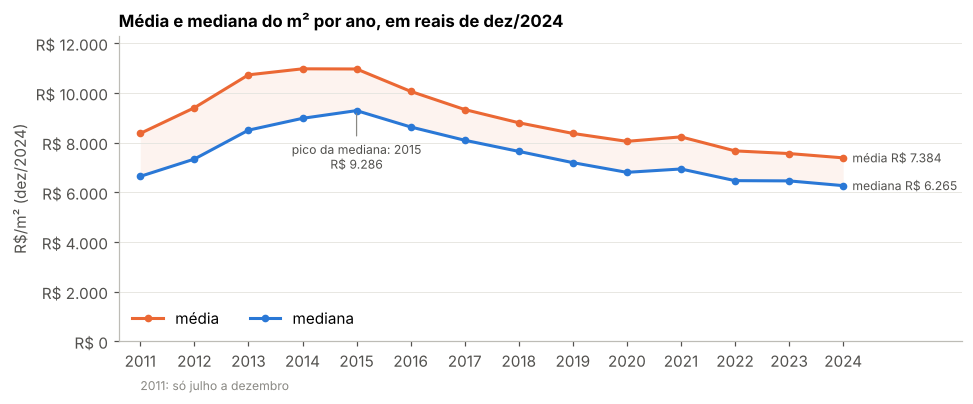

,transações,média,mediana,média / mediana
ano,,,,
2011,21.214,R$ 8.368,R$ 6.639,"1,26"
2012,39.438,R$ 9.401,R$ 7.336,"1,28"
2013,37.760,R$ 10.727,R$ 8.499,"1,26"
2014,31.458,R$ 10.969,R$ 8.975,"1,22"
2015,27.254,R$ 10.962,R$ 9.286,"1,18"
2016,22.875,R$ 10.062,R$ 8.628,"1,17"
2017,27.103,R$ 9.330,R$ 8.093,"1,15"
2018,24.502,R$ 8.798,R$ 7.644,"1,15"
2019,25.515,R$ 8.368,R$ 7.191,"1,16"


In [11]:
por_ano = df.groupby("ano").m2_real.agg(transações="size", média="mean", mediana="median")
por_ano["média / mediana"] = por_ano["média"] / por_ano["mediana"]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(por_ano.index, por_ano["média"], color=LARANJA, lw=2, marker="o", ms=4, label="média")
ax.plot(por_ano.index, por_ano["mediana"], color=AZUL, lw=2, marker="o", ms=4, label="mediana")
ax.fill_between(por_ano.index, por_ano["mediana"], por_ano["média"], color=LARANJA, alpha=0.08, lw=0)
for col, cor in [("média", LARANJA), ("mediana", AZUL)]:
    ax.annotate(f"{col} {reais(por_ano[col].iloc[-1])}", (por_ano.index[-1], por_ano[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=TINTA)
pico = por_ano["mediana"].idxmax()
ax.annotate(f"pico da mediana: {pico}\n{reais(por_ano.loc[pico, 'mediana'])}", (pico, por_ano.loc[pico, "mediana"]),
            xytext=(0, -38), textcoords="offset points", ha="center", fontsize=8, color=TINTA,
            arrowprops=dict(arrowstyle="-", color=CINZA, lw=0.8))
ax.set_xticks(por_ano.index)
ax.set_xlim(2010.6, 2026.2)
ax.set_ylim(0, por_ano["média"].max() * 1.12)
ax.yaxis.set_major_formatter(fmt_reais)
ax.grid(axis="x", visible=False)
ax.set_ylabel("R$/m² (dez/2024)")
ax.set_title("Média e mediana do m² por ano, em reais de dez/2024")
ax.legend(loc="lower left", ncol=2)
ax.text(2011, -0.16 * ax.get_ylim()[1], "2011: só julho a dezembro", fontsize=8, color=CINZA)
fig.tight_layout()
plt.show()

tabela(por_ano, {"transações": "{:,.0f}", "média": "R$ {:,.0f}", "mediana": "R$ {:,.0f}",
                      "média / mediana": "{:.2f}"})

## 4. Pergunta 3 — Dispersão

A pergunta pede variância, desvio padrão e amplitude. As três são calculadas abaixo, junto com duas medidas complementares:

- **Intervalo interquartil (IIQ)**: a distância entre o 1º e o 3º quartil, onde estão os 50% centrais das transações. Ao contrário das outras, não depende dos extremos.
- **Coeficiente de variação (CV)**: o desvio padrão dividido pela média. Permite comparar dispersão entre grupos com níveis de preço diferentes, o que será usado na pergunta 4.

Para mostrar o peso dos valores extremos, a tabela calcula tudo em três versões da base: completa (com os valores suspeitos), a base de análise e a base de análise sem o 1% mais baixo e o 1% mais alto.

In [12]:
def dispersao(s):
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({
        "transações": len(s),
        "variância": s.var(),
        "desvio padrão": s.std(),
        "mínimo": s.min(), "máximo": s.max(),
        "amplitude": s.max() - s.min(),
        "IIQ (Q3 − Q1)": q3 - q1,
        "CV": s.std() / s.mean(),
        "média": s.mean(), "mediana": s.median(),
    })

# base completa corrigida pela inflação, para comparação
completa = bruto.copy()
ind_b = np.array([indice_dez[a - 1] * (1 + IPCA[a] / 100) ** (m / 12) for a, m in zip(completa.ano, completa.mes)])
completa["m2_real"] = completa.valor_m2 * indice_dez[2024] / ind_b

p01, p99 = df.m2_real.quantile([.01, .99])
aparada = df.m2_real[df.m2_real.between(p01, p99)]

tab_disp = pd.DataFrame({
    "base completa (com suspeitos)": dispersao(completa.m2_real),
    "base de análise": dispersao(df.m2_real),
    "base de análise, sem 1% das pontas": dispersao(aparada),
}).T

fmt = {c: "{:,.0f}" for c in tab_disp.columns}
fmt["CV"] = "{:.2f}"
fmt["variância"] = "{:,.0f}"
print(f"Percentis de corte da versão aparada: P1 = {reais(p01)} · P99 = {reais(p99)}")
cols = ["ano", "nm_bairro_norm", "ds_imovel_tipologia", "area", "valor_transacoes", "m2_real"]
print("\n5 menores e 5 maiores m² da base de análise:")
print(pd.concat([df.nsmallest(5, "m2_real"), df.nlargest(5, "m2_real")])[cols].round(0).to_string())
tabela(tab_disp, fmt)

Percentis de corte da versão aparada: P1 = R$ 1.480 · P99 = R$ 32.169

5 menores e 5 maiores m² da base de análise:
         ano  nm_bairro_norm   ds_imovel_tipologia   area  valor_transacoes   m2_real
437502  2024      COPACABANA           APARTAMENTO   38.0           10851.0     287.0
429777  2024      COPACABANA           APARTAMENTO   39.0           11227.0     291.0
433943  2024      COPACABANA           APARTAMENTO   49.0           14319.0     295.0
420618  2024      COPACABANA           APARTAMENTO   34.0            9962.0     299.0
437171  2024     LARANJEIRAS                  CASA  139.0           41470.0     300.0
71777   2013          LEBLON                  CASA  380.0        27145064.0  138150.0
26580   2012         IPANEMA           APARTAMENTO  508.0        28000000.0  113918.0
36421   2012         IPANEMA           APARTAMENTO  311.0        17000000.0  111384.0
74496   2013  VARGEM PEQUENA  PROLETARIO CASA/APTO   52.0         3000000.0  111041.0
118204  2014         IPA

,transações,variância,desvio padrão,mínimo,máximo,amplitude,IIQ (Q3 − Q1),CV,média,mediana
base completa (com suspeitos),441.669,28.766.189.671,169.606,0,92.484.000,92.484.000,5.802,"17,94",9.455,7.392
base de análise,440.155,39.301.484,6.269,287,138.150,137.863,5.790,"0,70",8.926,7.407
"base de análise, sem 1% das pontas",431.351,26.538.091,5.152,1.480,32.169,30.689,5.642,"0,59",8.664,7.407


O boxplot abaixo resume a dispersão da base de análise na escala log. A caixa vai de Q1 a Q3 e as hastes vão do percentil 1 ao 99. Os pontos além delas são os 2% de transações que a versão aparada da tabela exclui, e é entre eles que estão o mínimo e o máximo que definem a amplitude.

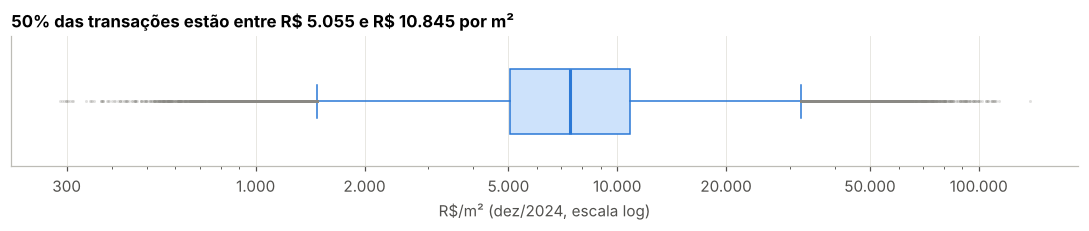

In [13]:
fig, ax = plt.subplots(figsize=(10, 2.2))
import warnings
warnings.filterwarnings("ignore", message=".*vert.*")   # aviso de versões novas do matplotlib
ax.boxplot(df.m2_real, vert=False, widths=0.5, patch_artist=True, whis=(1, 99),
           boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL, lw=1),
           medianprops=dict(color=AZUL, lw=2), whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
           flierprops=dict(marker="o", ms=2, mfc=CINZA, mec="none", alpha=0.25))
ax.set_xscale("log")
ax.set_xticks([300, 1000, 2000, 5000, 10000, 20000, 50000, 100000])
ax.xaxis.set_major_formatter(fmt_milhar)
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_xlabel("R$/m² (dez/2024, escala log)")
q1, q3 = df.m2_real.quantile([.25, .75])
ax.set_title(f"50% das transações estão entre {reais(q1)} e {reais(q3)} por m²")
fig.tight_layout()
plt.show()

A dispersão do período inteiro mistura duas fontes: a diferença entre imóveis num mesmo ano e a variação do preço real ao longo do tempo. Separando por ano, dá para ver qual das duas pesa mais.

In [14]:
disp_ano = df.groupby("ano").m2_real.apply(dispersao).unstack()[["transações", "desvio padrão", "IIQ (Q3 − Q1)", "CV", "mediana"]]
tabela(disp_ano, {"transações": "{:,.0f}", "desvio padrão": "R$ {:,.0f}", "IIQ (Q3 − Q1)": "R$ {:,.0f}",
                       "CV": "{:.2f}", "mediana": "R$ {:,.0f}"})

,transações,desvio padrão,IIQ (Q3 − Q1),CV,mediana
ano,,,,,
2011,21.214,R$ 6.242,R$ 5.328,"0,75",R$ 6.639
2012,39.438,R$ 7.108,R$ 6.034,"0,76",R$ 7.336
2013,37.760,R$ 7.796,R$ 7.194,"0,73",R$ 8.499
2014,31.458,R$ 7.693,R$ 6.851,"0,70",R$ 8.975
2015,27.254,R$ 7.264,R$ 6.680,"0,66",R$ 9.286
2016,22.875,R$ 6.326,R$ 6.057,"0,63",R$ 8.628
2017,27.103,R$ 5.705,R$ 5.363,"0,61",R$ 8.093
2018,24.502,R$ 5.396,R$ 5.200,"0,61",R$ 7.644
2019,25.515,R$ 5.440,R$ 5.074,"0,65",R$ 7.191


## 5. Pergunta 4 — A distribuição é semelhante entre regiões e bairros?

### 5.1 Áreas de Planejamento

In [15]:
def resumo(s):
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({"transações": len(s), "mediana": s.median(), "média": s.mean(),
                      "Q1": q1, "Q3": q3, "IIQ / mediana": (q3 - q1) / s.median(),
                      "CV": s.std() / s.mean(), "% casas": np.nan})

tab_ap = df.groupby("ap", observed=True).m2_real.apply(resumo).unstack()
tab_ap["% casas"] = df.groupby("ap", observed=True).ds_imovel_tipologia.apply(lambda s: (s != "APARTAMENTO").mean() * 100)
tab_ap["mediana / mediana da cidade"] = tab_ap["mediana"] / df.m2_real.median()

assim = df.groupby("ap", observed=True).m2_real.apply(lambda s: np.log(s).skew())
print("Assimetria do log(R$/m²) por AP:", " · ".join(f"{a.split(' ·')[0]} {v:.2f}" for a, v in assim.items()))
tabela(tab_ap, {"transações": "{:,.0f}", "mediana": "R$ {:,.0f}", "média": "R$ {:,.0f}",
                     "Q1": "R$ {:,.0f}", "Q3": "R$ {:,.0f}", "IIQ / mediana": "{:.2f}", "CV": "{:.2f}",
                     "% casas": "{:.0f}%", "mediana / mediana da cidade": "{:.2f}"})

Assimetria do log(R$/m²) por AP: AP1 -0.85 · AP2 -0.30 · AP3 -0.67 · AP4 -0.39 · AP5 -0.41


,transações,mediana,média,Q1,Q3,IIQ / mediana,CV,% casas,mediana / mediana da cidade
ap,,,,,,,,,
AP1 · Centro,23.251,R$ 8.114,R$ 8.210,R$ 5.565,R$ 10.067,"0,55","0,52",8%,"1,10"
AP2 · Zona Sul e Tijuca,119.263,R$ 12.161,R$ 14.014,R$ 8.532,R$ 17.463,"0,73","0,60",4%,"1,64"
AP3 · Zona Norte,103.501,R$ 5.495,R$ 5.672,R$ 3.785,R$ 7.183,"0,62","0,47",22%,"0,74"
AP4 · Barra e Jacarepaguá,157.315,R$ 7.685,R$ 8.397,R$ 5.849,R$ 10.164,"0,56","0,47",12%,"1,04"
AP5 · Zona Oeste,36.733,R$ 4.067,R$ 4.308,R$ 3.083,R$ 5.160,"0,51","0,62",45%,"0,55"


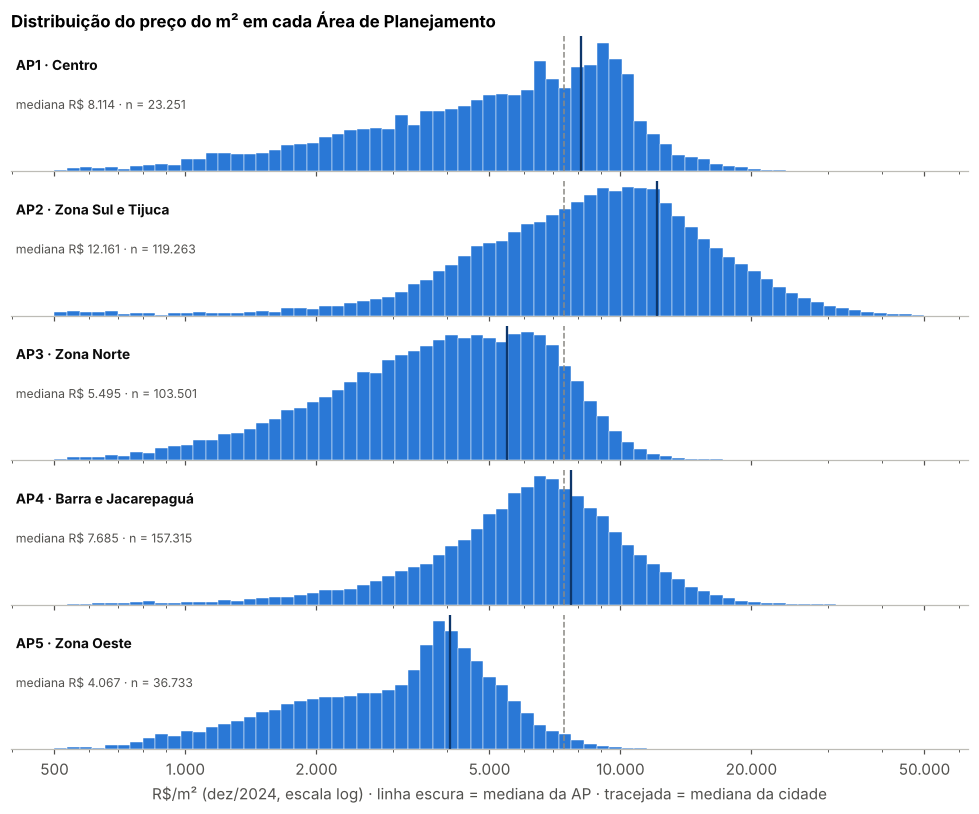

In [16]:
# Pequenos múltiplos: um histograma por AP, mesmo eixo x (log), para comparar posição e forma
aps = [a for a in ORDEM_AP if a in df.ap.cat.categories]
bins = np.logspace(np.log10(500), np.log10(50000), 70)
med_cidade = df.m2_real.median()

fig, axs = plt.subplots(len(aps), 1, figsize=(9, 7.5), sharex=True)
for ax, a in zip(axs, aps):
    v = df.loc[df.ap == a, "m2_real"]
    ax.hist(v, bins=bins, density=True, color=AZUL, edgecolor="white", linewidth=0.3)
    ax.axvline(v.median(), color="#0d366b", lw=1.5)
    ax.axvline(med_cidade, color=CINZA, lw=1, ls="--")
    ax.set_yticks([]); ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.text(0.005, 0.85, a, transform=ax.transAxes, fontsize=9, fontweight="bold", color="#0b0b0b", va="top")
    ax.text(0.005, 0.55, f"mediana {reais(v.median())} · n = {len(v):,}".replace(",", "."),
            transform=ax.transAxes, fontsize=8, color=TINTA, va="top")
axs[-1].set_xscale("log")
axs[-1].set_xticks([500, 1000, 2000, 5000, 10000, 20000, 50000])
axs[-1].xaxis.set_major_formatter(fmt_milhar)
axs[-1].set_xlabel("R$/m² (dez/2024, escala log) · linha escura = mediana da AP · tracejada = mediana da cidade")
axs[0].set_title("Distribuição do preço do m² em cada Área de Planejamento")
fig.tight_layout(h_pad=0.3)
plt.show()

A AP5 tem uma proporção de casas bem maior que a AP2, e casas têm m² mais barato. Parte da diferença entre regiões poderia vir só dessa composição. Para separar os dois efeitos, comparamos as medianas por tipo de imóvel dentro de cada AP:

In [17]:
tab_tipo_ap = (df[df.ds_imovel_tipologia.isin(["APARTAMENTO", "CASA"])]
               .pivot_table(index="ap", columns="ds_imovel_tipologia", values="m2_real",
                            aggfunc="median", observed=True))
tab_tipo_ap.columns = ["mediana apartamentos", "mediana casas"]
tab_tipo_ap["apto / mediana de aptos na cidade"] = tab_tipo_ap["mediana apartamentos"] / df.loc[df.ds_imovel_tipologia == "APARTAMENTO", "m2_real"].median()
tabela(tab_tipo_ap, {"mediana apartamentos": "R$ {:,.0f}", "mediana casas": "R$ {:,.0f}",
                          "apto / mediana de aptos na cidade": "{:.2f}"})

,mediana apartamentos,mediana casas,apto / mediana de aptos na cidade
ap,,,
AP1 · Centro,R$ 8.348,R$ 3.774,"1,05"
AP2 · Zona Sul e Tijuca,R$ 12.314,R$ 7.759,"1,55"
AP3 · Zona Norte,R$ 5.856,R$ 3.979,"0,74"
AP4 · Barra e Jacarepaguá,R$ 7.919,R$ 5.648,"1,00"
AP5 · Zona Oeste,R$ 4.262,R$ 3.774,"0,54"


### 5.2 Bairros

Comparamos apenas bairros com pelo menos 200 transações no período, cerca de 14 por ano, para que a mediana de cada um seja estável. O gráfico mostra os 15 bairros mais caros e os 15 mais baratos. O ponto marca a mediana e a barra vai do 1º ao 3º quartil.

Bairros com transações: 156 · com pelo menos 200: 135 (99.6% das transações)


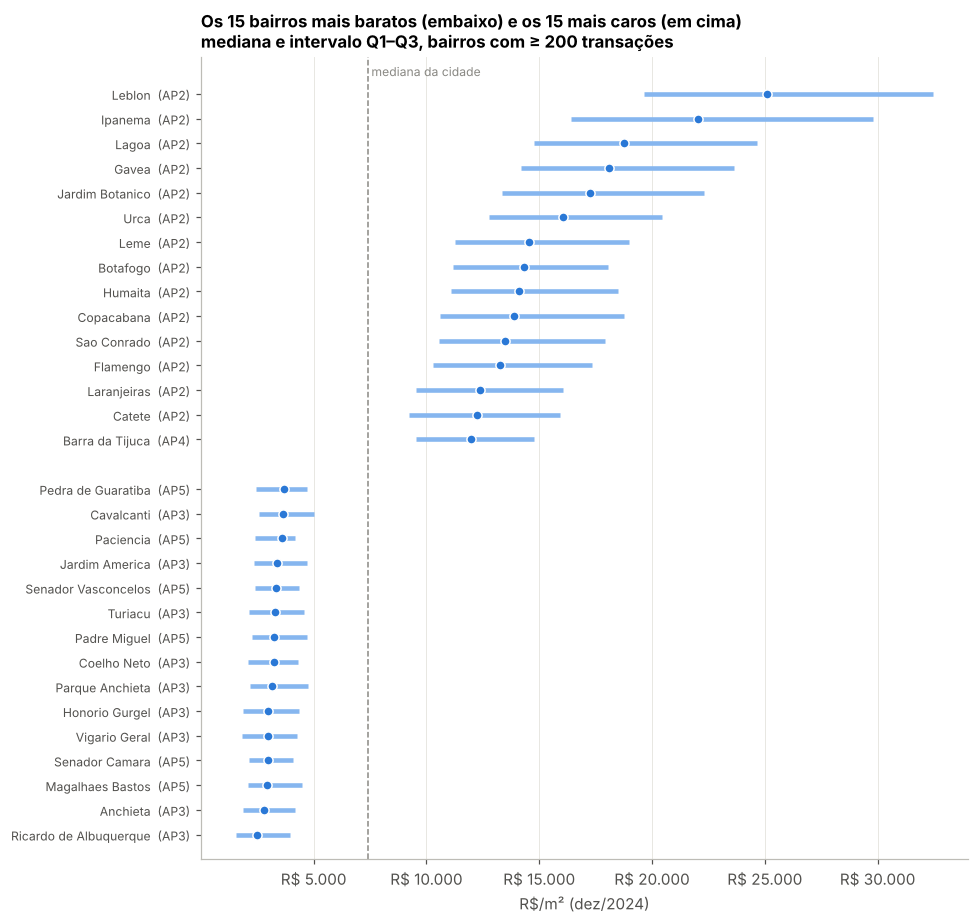

Mais caro: Leblon (R$ 25.079) · mais barato: Ricardo de Albuquerque (R$ 2.501) · razão 10.0×


In [18]:
N_MIN = 200
por_bairro = (df.dropna(subset=["nm_bairro_norm"]).groupby("nm_bairro_norm")
              .agg(transações=("m2_real", "size"), mediana=("m2_real", "median"),
                   Q1=("m2_real", lambda s: s.quantile(.25)), Q3=("m2_real", lambda s: s.quantile(.75)),
                   ap=("ap", "first")))
elegiveis = por_bairro[por_bairro["transações"] >= N_MIN].sort_values("mediana")
print(f"Bairros com transações: {len(por_bairro)} · com pelo menos {N_MIN}: {len(elegiveis)} "
      f"({elegiveis['transações'].sum() / len(df):.1%} das transações)")

extremos = pd.concat([elegiveis.head(15), elegiveis.tail(15)])
fig, ax = plt.subplots(figsize=(9, 8.5))
y = np.arange(len(extremos))
y = np.where(y >= 15, y + 1, y)   # espaço entre os dois grupos
ax.hlines(y, extremos.Q1, extremos.Q3, color="#86b6ef", lw=3)
ax.plot(extremos.mediana, y, "o", color=AZUL, ms=6, mec="white", mew=1)
ax.set_yticks(y)
ax.set_yticklabels([f"{nome(b)}  ({a.split(' ·')[0]})" for b, a in zip(extremos.index, extremos.ap)], fontsize=8)
ax.axvline(df.m2_real.median(), color=CINZA, lw=1, ls="--")
ax.text(df.m2_real.median(), len(extremos) + 0.6, " mediana da cidade", fontsize=8, color=CINZA, va="bottom")
ax.xaxis.set_major_formatter(fmt_reais)
ax.grid(axis="y", visible=False)
ax.set_xlabel("R$/m² (dez/2024)")
ax.set_title(f"Os 15 bairros mais baratos (embaixo) e os 15 mais caros (em cima)\nmediana e intervalo Q1–Q3, bairros com ≥ {N_MIN} transações")
ax.set_ylim(-1, len(extremos) + 1.5)
fig.tight_layout()
plt.show()

razao = elegiveis.mediana.iloc[-1] / elegiveis.mediana.iloc[0]
print(f"Mais caro: {nome(elegiveis.index[-1])} ({reais(elegiveis.mediana.iloc[-1])}) · "
      f"mais barato: {nome(elegiveis.index[0])} ({reais(elegiveis.mediana.iloc[0])}) · razão {razao:.1f}×")

### 5.3 Quanto da variação de preço é explicada pela localização?

Uma forma simples de medir se os grupos são parecidos é perguntar que fração da variação total do preço é diferença **entre** grupos, e não variação **dentro** de cada grupo. Essa fração é o η² (eta ao quadrado): a soma dos quadrados entre grupos dividida pela soma dos quadrados total. Se todos os bairros tivessem a mesma distribuição, η² seria zero. Se todo imóvel valesse exatamente a mediana do seu bairro, seria 1.

Calculamos sobre o logaritmo do preço, porque na escala log a distribuição é quase simétrica e uma diferença de 2× pesa igual em qualquer faixa de preço.

In [19]:
def eta2(valores, grupos):
    d = pd.DataFrame({"v": valores, "g": grupos}).dropna()
    media_g = d.groupby("g", observed=True).v.transform("mean")
    return ((media_g - d.v.mean()) ** 2).sum() / ((d.v - d.v.mean()) ** 2).sum()

log_p = np.log(df.m2_real)
tab_eta = pd.Series({
    "Área de Planejamento (5 grupos)": eta2(log_p, df.ap),
    "Bairro (156 grupos)": eta2(log_p, df.nm_bairro_norm),
    "Ano da transação (14 grupos)": eta2(log_p, df.ano),
    "Tipo de imóvel (apto × casa × proletário)": eta2(log_p, df.ds_imovel_tipologia),
}, name="η² sobre log(R$/m²)").to_frame()
tabela(tab_eta, "{:.1%}")

,η² sobre log(R$/m²)
Área de Planejamento (5 grupos),"34,4%"
Bairro (156 grupos),"55,6%"
Ano da transação (14 grupos),"5,0%"
Tipo de imóvel (apto × casa × proletário),"12,2%"
